# Laboratorium 3 — Otwarte dane i wartości odstające

**Eksploracja danych** · dr Paweł Gliwny · WFiIS UŁ

Na tych zajęciach:

1. **Część 1** — pobierzesz dane z portalu otwartych danych Łodzi, wczytasz je, zmienisz ich format, policzysz statystyki zbiorcze i zrobisz proste wykresy.
2. **Część 2** — na danych o pacjentach przejdziesz kolejne kroki wykrywania wartości odstających: od najprostszych do bardziej złożonych.

Miejsca do uzupełnienia oznaczone są `# TODO`. Odpowiedzi na pytania wpisuj w komórkach tekstowych oznaczonych ✍️.

> Notatnik po zajęciach umieść w swoim repozytorium na GitHubie.

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams["figure.dpi"] = 100

In [11]:
def upewnij_sie_ze_jest(nazwa_pliku):
    # W Colabie: jeśli pliku nie ma, otwiera okno wgrywania pliku.
    if Path(nazwa_pliku).exists():
        print(f"Plik {nazwa_pliku} jest na miejscu.")
        return
    try:
        from google.colab import files
        print(f"Wgraj plik {nazwa_pliku}:")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Umieść plik {nazwa_pliku} w folderze z notatnikiem.")

---
# Część 1. Dane z portalu otwartych danych Łodzi

Portal: [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl)

Zaczynamy od wspólnego przykładu — pliku `szkolnictwo_wysze.csv` (szkolnictwo wyższe w Łodzi w latach 2012–2024). Pobierz go z portalu albo od prowadzącego i wgraj do Colaba (ikona folderu po lewej lub komórka poniżej).

In [12]:
PLIK_LODZ = "szkolnictwo_wysze.csv"
upewnij_sie_ze_jest(PLIK_LODZ)

Plik szkolnictwo_wysze.csv jest na miejscu.


## 1.1 Wczytanie danych

Zanim wywołasz `read_csv`, obejrzyj surowy plik — pierwsze linie tekstu powiedzą, jaki jest separator.

In [13]:
# podgląd surowego pliku
with open(PLIK_LODZ, encoding="utf-8") as f:
    for _ in range(5):
        print(f.readline().rstrip())

name;rok;wartość;zmienna
Szkolnictwo wyższe;2012;22;uczelnie
Szkolnictwo wyższe;2013;22;uczelnie
Szkolnictwo wyższe;2014;23;uczelnie
Szkolnictwo wyższe;2015;21;uczelnie


In [14]:
# TODO: wczytaj plik do ramki `df` z właściwym separatorem
df = pd.read_csv(PLIK_LODZ, sep=";")

# TODO: wyświetl pierwsze wiersze, wymiary i typy kolumn
display(df.head())
print("Wymiary: ", df.shape)
print(df.dtypes)


,name,rok,wartość,zmienna
0,Szkolnictwo wyższe,2012,22,uczelnie
1,Szkolnictwo wyższe,2013,22,uczelnie
2,Szkolnictwo wyższe,2014,23,uczelnie
3,Szkolnictwo wyższe,2015,21,uczelnie
4,Szkolnictwo wyższe,2016,20,uczelnie


Wymiary:  (65, 4)
name       object
rok         int64
wartość     int64
zmienna    object
dtype: object


✍️ **Pytanie:** Jaki jest separator? Czy kolumna `wartość` ma typ liczbowy? Czy nazwy kolumn z polskimi znakami wczytały się poprawnie?

*Odpowiedź:* Separator to ";", ma typ liczbowy int, nazwy wczytały sie poprawnie.

## 1.2 Format długi czy szeroki?

Przypomnienie z wykładu 2: w formacie **długim** każdy wiersz to jedna para (zmienna, wartość); w formacie **szerokim** każda zmienna ma własną kolumnę.

1. Sprawdź, jakie wartości przyjmuje kolumna `zmienna` i ile razy każda występuje.
2. Przekształć dane do formatu szerokiego: wiersze = lata, kolumny = zmienne.

In [15]:
# TODO: jakie są zmienne i ile mają wierszy?
print(df["zmienna"].value_counts())

# TODO: format szeroki (pivot) — wynik zapisz w `szeroka`
szeroka = df.pivot(index="rok", columns="zmienna", values="wartość")
print(szeroka)

zmienna
uczelnie             13
ogółem               13
kobiety              13
mężczyźni            13
absolwenci ogółem    13
Name: count, dtype: int64
zmienna  absolwenci ogółem  kobiety  mężczyźni  ogółem  uczelnie
rok                                                             
2012                 24825    55265      36281   91546        22
2013                 22590    50007      33464   83471        22
2014                 21343    48220      32456   80676        23
2015                 19835    45584      30769   76353        21
2016                 17662    44053      29908   73961        20
2017                 19281    42990      29029   72019        22
2018                 17046    39312      26253   65565        20
2019                 15819    38146      26297   64443        19
2020                 14082    39170      26155   65325        18
2021                 14756    39958      26044   66002        17
2022                 14479    38484      26049   64533        18
2

## 1.3 Czy dane są spójne?

Liczba studentów `ogółem` powinna być sumą `kobiety` i `mężczyźni`. Sprawdź to dla każdego roku.

In [16]:
# TODO: policz różnicę (kobiety + mężczyźni) − ogółem dla każdego roku
suma = szeroka["kobiety"] + szeroka["mężczyźni"]
print(suma)
roznica = suma - szeroka["ogółem"]
print(roznica)

rok
2012    91546
2013    83471
2014    80676
2015    76353
2016    73961
2017    72019
2018    65565
2019    64443
2020    65325
2021    66002
2022    64533
2023    65297
2024    64272
dtype: int64
rok
2012    0
2013    0
2014    0
2015    0
2016    0
2017    0
2018    0
2019    0
2020    0
2021    0
2022    0
2023    0
2024    0
dtype: int64


## 1.4 Statystyki zbiorcze

1. Policz statystyki opisowe dla wszystkich zmiennych (`describe`).
2. O ile procent zmieniła się każda zmienna między 2012 a 2024 rokiem?
3. Dodaj kolumnę `udzial_kobiet` (udział kobiet wśród studentów) i kolumnę `studenci_na_uczelnie`.

In [17]:
# TODO: statystyki opisowe
opis = szeroka.describe()
print(opis)

# TODO: zmiana procentowa 2012 → 2024
procentowa_zmiana = (szeroka.loc[2024] - szeroka.loc[2012]) / szeroka.loc[2012] * 100
print(procentowa_zmiana)
# TODO: nowe kolumny
szeroka["udzial_kobiet"] = szeroka["kobiety"] / szeroka["ogółem"]
szeroka["studenci_na_uczelnie"] = szeroka["ogółem"] / szeroka["uczelnie"]
display(szeroka.head())

zmienna  absolwenci ogółem  kobiety  mężczyźni   ogółem  uczelnie
count                13.00    13.00      13.00    13.00     13.00
mean              17780.54 43010.92   28793.92 71804.85     19.54
std                3522.40  5391.05    3524.63  8900.65      2.44
min               14082.00 38146.00   25710.00 64272.00     15.00
25%               14756.00 39170.00   26049.00 65297.00     18.00
50%               17046.00 39958.00   26297.00 66002.00     20.00
75%               19835.00 45584.00   30769.00 76353.00     22.00
max               24825.00 55265.00   36281.00 91546.00     23.00
zmienna
absolwenci ogółem   -41.29
kobiety             -30.22
mężczyźni           -29.14
ogółem              -29.79
uczelnie            -31.82
dtype: float64


zmienna,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie,udzial_kobiet,studenci_na_uczelnie
rok,,,,,,,
2012,24825,55265,36281,91546,22,0.60,4161.18
2013,22590,50007,33464,83471,22,0.60,3794.14
2014,21343,48220,32456,80676,23,0.60,3507.65
2015,19835,45584,30769,76353,21,0.60,3635.86
2016,17662,44053,29908,73961,20,0.60,3698.05


## 1.5 Wykresy

Narysuj trzy wykresy (najlepiej obok siebie, `plt.subplots(1, 3)`):

1. liczba studentów w czasie — osobne linie dla kobiet i mężczyzn,
2. liczba uczelni w czasie,
3. udział kobiet wśród studentów (oś Y od 0 do 1).

Każdy wykres podpisz: tytuł, opisy osi.

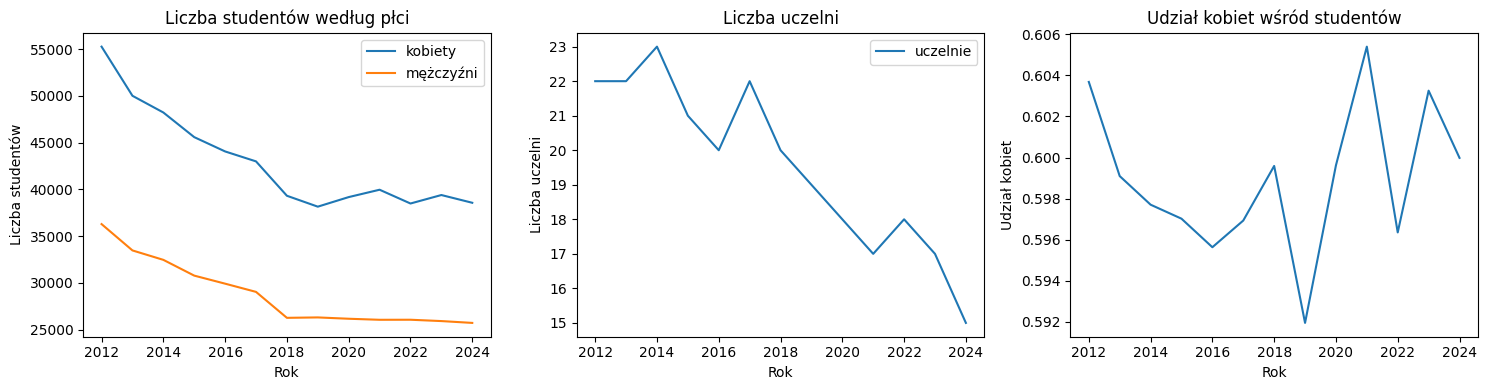

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# TODO: wykres 1 — kobiety i mężczyźni
for zmienna in ["kobiety", "mężczyźni"]:
    axes[0].plot(szeroka.index, szeroka[zmienna], label=zmienna)
axes[0].set_title("Liczba studentów według płci") 
axes[0].set_xlabel("Rok")
axes[0].set_ylabel("Liczba studentów")
axes[0].legend()
# TODO: wykres 2 — uczelnie
for zmienna in ["uczelnie"]:
    axes[1].plot(szeroka.index, szeroka[zmienna], label=zmienna)
axes[1].set_title("Liczba uczelni")
axes[1].set_xlabel("Rok")
axes[1].set_ylabel("Liczba uczelni")
axes[1].legend()

# TODO: wykres 3 — udział kobiet
for zmienna in ["udzial_kobiet"]:
    axes[2].plot(szeroka.index, szeroka[zmienna], label=zmienna)
axes[2].set_title("Udział kobiet wśród studentów")
axes[2].set_xlabel("Rok")
axes[2].set_ylabel("Udział kobiet")

plt.tight_layout()
plt.show()

✍️ **Wnioski** (3 zdania): co się stało ze szkolnictwem wyższym w Łodzi w latach 2012–2024?

*Odpowiedź:* Szkolnictwo wyższe w łodzi zanotowało regres. Ogólna liczba studentów spadła oraz sama liczba uczelni wyraznie zmalała. Mimo to kobiety przez cały okres stanowiły ok. 60% studentów.

## 1.6 Zadanie samodzielne: Twój zbiór z portalu Łodzi

Wybierz **inny** zbiór z [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl) i przejdź te same kroki:

1. Podaj nazwę zbioru, link i datę pobrania.
2. Wczytaj plik (separator? kodowanie? przecinek dziesiętny?).
3. Ustal, czy dane są w formacie długim, czy szerokim; w razie potrzeby przekształć.
4. Sprawdź braki (`isna().sum()`) i spójność danych.
5. Policz statystyki zbiorcze.
6. Zrób 2–3 podpisane wykresy i napisz 2–3 zdania wniosków.

✍️ **Zbiór:** Dochody miasta na 1 mieszkanca· **link:** https://otwarte.miasto.lodz.pl/dochody_miasta/· **data pobrania:** 28.10.2026

In [31]:
# TODO: wczytanie i przegląd Twojego zbioru
PLIK_WLASNY = "dochody-miasta-na-1-mieszkaca.csv"
upewnij_sie_ze_jest(PLIK_WLASNY)

with open(PLIK_WLASNY, encoding="utf-8") as f:
    for _ in range(5):
        print(f.readline().rstrip())
df = pd.read_csv(PLIK_WLASNY, sep=";", decimal=",")
display(df.head())
print("Dane sa w formacie długim \n")
print("Wymiary: ", df.shape, '\n')
print(df.dtypes)
print("\nbraki: ")
print(df.isna().sum())


Plik dochody-miasta-na-1-mieszkaca.csv jest na miejscu.
﻿id;name;rok;wartość;zmienne
76974;Finanse Publiczne;2002;1941;dochody miasta na 1 mieszkańca
76974;Finanse Publiczne;2003;1936;dochody miasta na 1 mieszkańca
76974;Finanse Publiczne;2004;2173;dochody miasta na 1 mieszkańca
76974;Finanse Publiczne;2005;2397;dochody miasta na 1 mieszkańca


,id,name,rok,wartość,zmienne
0,76974,Finanse Publiczne,2002,1941.00,dochody miasta na 1 mieszkańca
1,76974,Finanse Publiczne,2003,1936.00,dochody miasta na 1 mieszkańca
2,76974,Finanse Publiczne,2004,2173.00,dochody miasta na 1 mieszkańca
3,76974,Finanse Publiczne,2005,2397.00,dochody miasta na 1 mieszkańca
4,76974,Finanse Publiczne,2006,2761.06,dochody miasta na 1 mieszkańca


Dane sa w formacie długim 

Wymiary:  (23, 5) 

id           int64
name        object
rok          int64
wartość    float64
zmienne     object
dtype: object

braki: 
id         0
name       0
rok        0
wartość    0
zmienne    0
dtype: int64


count      23.00
mean     4968.07
std      2359.29
min      1936.00
25%      3225.93
50%      4793.75
75%      6264.26
max     10253.68
Name: wartość, dtype: float64
procentowa_zmiana:  144.31 %


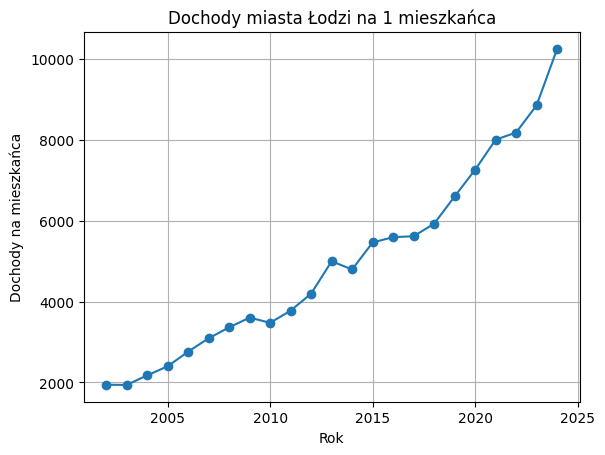

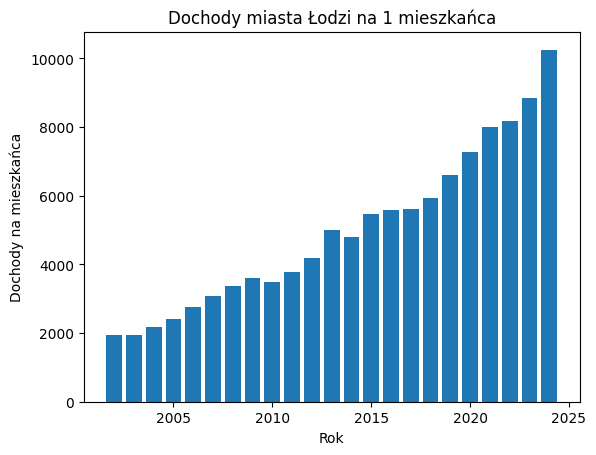

In [36]:
# TODO: przekształcenia, statystyki i wykresy
opis = df["wartość"].describe()
print(opis)
dochod_2012 = df.loc[df["rok"]==2012, "wartość"].iloc[0]
dochod_2024 = df.loc[df["rok"]==2024, "wartość"].iloc[0]

zmiana = (dochod_2024-dochod_2012) / dochod_2012 * 100
print("procentowa_zmiana: ", zmiana.round(2), "%")

#wykres punktowy
plt.plot(df["rok"], df["wartość"], marker="o")
plt.title("Dochody miasta Łodzi na 1 mieszkańca")
plt.xlabel("Rok")
plt.ylabel("Dochody na mieszkańca")
plt.grid("True")
plt.show()
#wykres słupkowy
plt.bar(df["rok"], df["wartość"])
plt.title("Dochody miasta Łodzi na 1 mieszkańca")
plt.xlabel("Rok")
plt.ylabel("Dochody na mieszkańca")
plt.show()

✍️ **Wnioski:** Dochody miasta Łodzi na 1 mieszkańca w latach 2002-2024 rosły. Największy wzrost nastąpił między 2023 a 2024.

---
# Część 2. Wartości odstające — dane o pacjentach

Zbiór: 3000 pacjentów z kolumnami `age` (wiek), `bmi`, `avg_glucose_level` (średni poziom glukozy we krwi, mg/dl), `hypertension`, `heart_disease`, `work_type` (rodzaj pracy), `smoking_status` (palenie), `stroke` (udar: 1/0) i kilkoma innymi.

> ⚠️ To **dane syntetyczne** — wygenerowane i celowo „zepsute” do ćwiczeń. Nie wyciągamy z nich wniosków medycznych.
>
> Źródło: deepsense.ai, *EDA Benchmark*, zadanie `identify-unusual-values` ([github.com/deepsense-ai/eda-benchmark](https://github.com/deepsense-ai/eda-benchmark)), licencja CC BY-NC-ND 4.0.

Plan — od najprostszej metody do najbardziej złożonej:

| Krok | Metoda |
|---|---|
| 1 | wartości niemożliwe — progi z wiedzy dziedzinowej |
| 2 | wartości skrajne w jednej zmiennej — wykresy, potem IQR, z-score, MAD |
| 3 | nielogiczne kombinacje kategorii — reguły |
| 4 | nietypowe kombinacje liczb — odległość od środka |
| 5 | decyzja: co zrobić z każdą grupą |

In [37]:
URL = ("https://raw.githubusercontent.com/deepsense-ai/eda-benchmark/main/"
       "tasks/identify-unusual-values/environment/dataset/synthetic_stroke_data.csv")

pacjenci = pd.read_csv(URL)
oryginal = pacjenci.copy()      # kopia surowych danych — przyda się na końcu
pacjenci.head()

,patient_id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,A456281,Male,25.00,0,0,False,student,Urban,77.47,35.66,formerly smoked,0
1,A730553,Male,16.00,0,0,True,student,Urban,83.78,34.76,never smoked,0
2,A800980,Male,19.00,0,0,True,Private,Urban,91.65,25.38,never smoked,0
3,A433166,Male,35.00,0,0,True,Self-employed,Urban,97.09,21.26,never smoked,0
4,A114521,Male,15.00,0,0,True,student,Urban,89.17,22.27,formerly smoked,0


## 2.0 Pierwszy rzut oka

Wyświetl statystyki opisowe kolumn liczbowych `age`, `bmi`, `avg_glucose_level` i narysuj ich histogramy.

          age     bmi  avg_glucose_level
count 3000.00 3000.00            3000.00
mean    45.25   26.29             134.00
std     20.83   15.88             181.27
min      0.67   -5.20             -21.40
25%     28.00   21.28              85.59
50%     49.00   24.70             101.40
75%     63.00   28.88             127.43
max     80.00  105.60            1254.60


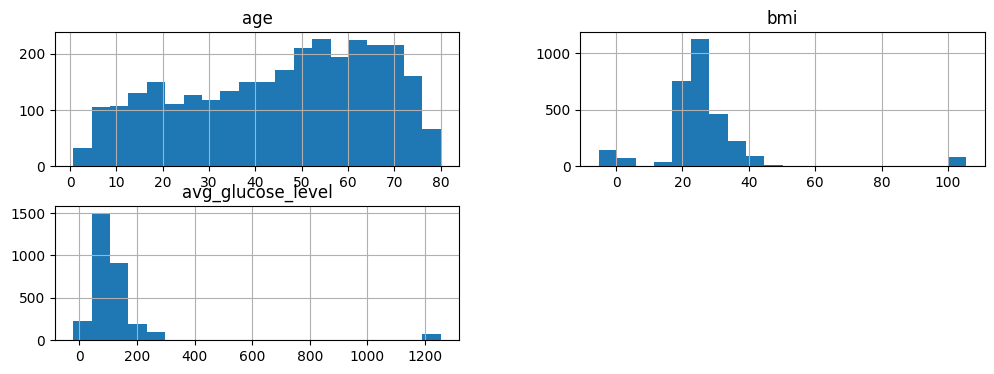

In [42]:
LICZBOWE = ["age", "bmi", "avg_glucose_level"]

# TODO: statystyki opisowe
opis = pacjenci[LICZBOWE].describe()
print(opis)

# TODO: histogramy (np. pacjenci[LICZBOWE].hist(...))
pacjenci[LICZBOWE].hist(figsize=(12,4), bins=20)
plt.show()

✍️ **Pytanie:** Które wartości minimalne i maksymalne są w ogóle *możliwe* u człowieka?

*Odpowiedź:* Wiek pacjentów mieści się w realistycznym zakresie. W kolumnie BMI występują wartości ujemne, które są biologicznie niemożliwe, oraz skrajnie wysokie wartości około 100. W kolumnie średniego poziomu glukozy widoczne są wartości około 1200, które znacząco odbiegają od pozostałych obserwacji

## 2.1 Krok 1: wartości niemożliwe

Przyjmujemy progi:

| Zmienna | Zakres możliwy |
|---|---|
| `bmi` | 10–60 |
| `avg_glucose_level` | 20–800 mg/dl |
| `age` | 0–120 lat |

Wartości spoza zakresu to **szum techniczny**, a nie rzadcy pacjenci — zamieniamy je na `NaN`.

1. Utwórz maski `zle_bmi`, `zla_glukoza`, `zly_wiek` (przyda się `Series.between`).
2. Policz, ile wartości jest niemożliwych w każdej kolumnie i ilu pacjentów ma co najmniej jedną taką wartość.
3. Zamień niemożliwe wartości na `NaN`.

In [45]:
# TODO: maski
zle_bmi = ~pacjenci["bmi"].between(10,60)
zla_glukoza = ~pacjenci["avg_glucose_level"].between(20, 800)
zly_wiek = ~pacjenci["age"].between(0,120)

# TODO: liczebności
print("Złe BMI: ", zle_bmi.sum())
print("Zła glukoza: ", zla_glukoza.sum())
print("Zły wiek: ", zly_wiek.sum())

zly_pacjent = zle_bmi | zly_wiek | zla_glukoza
print("Pacjent z błędem: ", zly_pacjent.sum())

# TODO: zamiana na NaN
pacjenci.loc[zle_bmi, "bmi"] = float("nan")
pacjenci.loc[zly_wiek, "age"] = float("nan")
pacjenci.loc[zla_glukoza, "avg_glucose_level"] = float("nan")
print(pacjenci[LICZBOWE].isna().sum())

Złe BMI:  300
Zła glukoza:  300
Zły wiek:  0
Pacjent z błędem:  560
age                    0
bmi                  300
avg_glucose_level    300
dtype: int64


          age     bmi  avg_glucose_level
count 3000.00 2700.00            2700.00
mean    45.25   26.12             116.84
std     20.83    5.84              44.45
min      0.67   13.57              44.76
25%     28.00   21.94              89.47
50%     49.00   24.98             103.09
75%     63.00   28.85             127.84
max     80.00   47.62             332.91


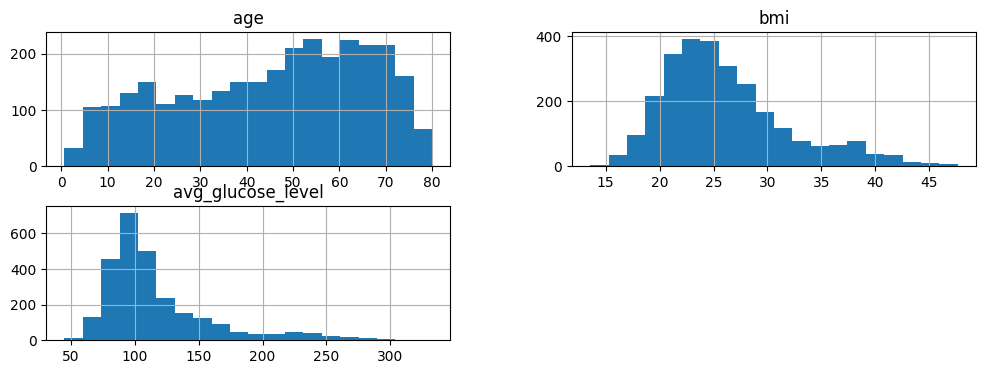

In [46]:
# TODO: ponownie statystyki opisowe i histogramy — co się zmieniło?

# Statystyki po oczyszczeniu
opis = pacjenci[LICZBOWE].describe()
print(opis)

# Histogramy po oczyszczeniu
pacjenci[LICZBOWE].hist(figsize=(12, 4), bins=20)
plt.show()


## 2.2 Krok 2a: wartości skrajne w jednej zmiennej — wykresy

Zanim cokolwiek policzysz, **obejrzyj** dane.

1. Narysuj obok siebie poziome wykresy pudełkowe dla `bmi` i `avg_glucose_level` (`plt.subplots(1, 2)`, `ax.boxplot(..., orientation="horizontal")`). Pamiętaj o `dropna()`.
2. Narysuj obok siebie dwa wykresy punktowe: `age` × `avg_glucose_level` i `age` × `bmi`.

Podpisz osie (z jednostkami) i nadaj tytuły.

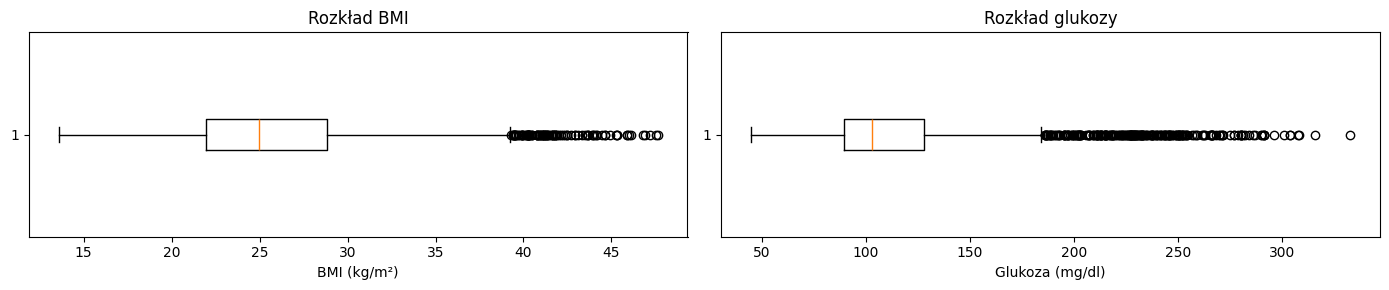

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3))

# TODO: wykresy pudełkowe bmi i glukozy
axes[0].boxplot(pacjenci["bmi"].dropna(), orientation="horizontal")
axes[0].set_title("Rozkład BMI")
axes[0].set_xlabel("BMI (kg/m²)")

# Wykres pudełkowy glukozy
axes[1].boxplot(pacjenci["avg_glucose_level"].dropna(), orientation="horizontal")
axes[1].set_title("Rozkład glukozy")
axes[1].set_xlabel("Glukoza (mg/dl)")

plt.tight_layout()
plt.show()

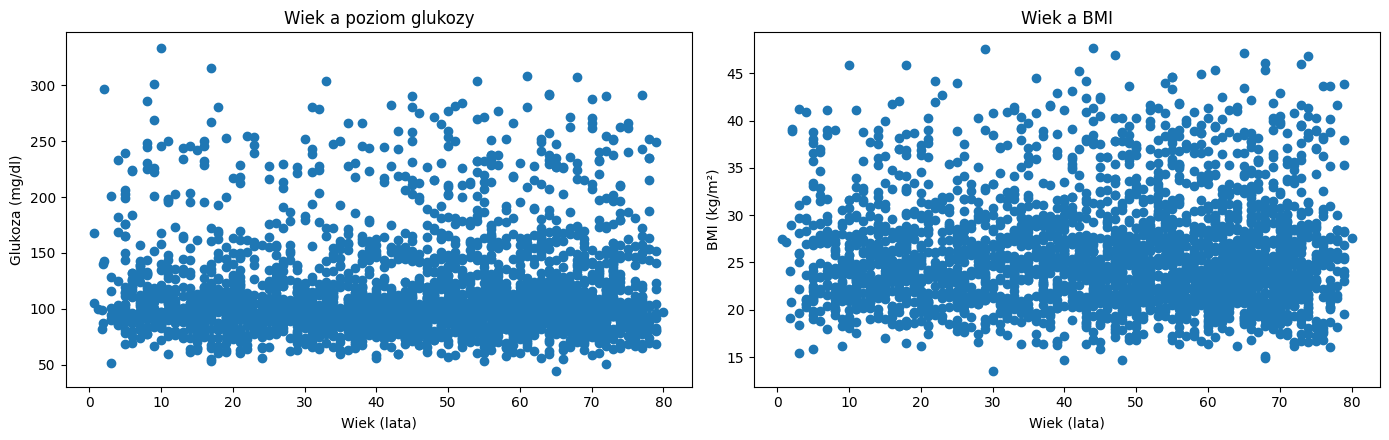

<Figure size 640x480 with 0 Axes>

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# TODO: wykresy punktowe age × glukoza i age × bmi
# Wiek a glukoza
axes[0].scatter(pacjenci["age"], pacjenci["avg_glucose_level"])
axes[0].set_title("Wiek a poziom glukozy")
axes[0].set_xlabel("Wiek (lata)")
axes[0].set_ylabel("Glukoza (mg/dl)")

# Wiek a BMI
axes[1].scatter(pacjenci["age"], pacjenci["bmi"])
axes[1].set_title("Wiek a BMI")
axes[1].set_xlabel("Wiek (lata)")
axes[1].set_ylabel("BMI (kg/m²)")

plt.tight_layout()
plt.show()


plt.tight_layout()
plt.show()

✍️ **Pytania:**
1. Dla której zmiennej jest więcej punktów poza wąsami? Czy leżą po obu stronach pudełka, czy tylko po jednej?
2. Na wykresie punktowym: czy wysokie wartości glukozy występują tylko w określonym wieku? Czy 10-latek ze średnią glukozą ponad 300 mg/dl to błąd, czy rzadki przypadek?

*Odpowiedź:* 
1. Na wykresie glukozy widać więcej punktów odstających niż na wykresie BMI. W obu przypadkach punkty odstające znajdują się tylko po prawej stronie pudełka, czyli dotyczą wysokich wartości.
2. Nie. Wysokie wartości glukozy występują u pacjentów w różnych grupach wiekowych. Niekoniecznie. Jest to bardzo wysoka, nieprawidłowa wartość, ale nie można na podstawie samego wykresu uznać jej za błąd pomiarowy.

## 2.3 Krok 2b: wartości skrajne w jednej zmiennej — metody liczbowe

Napisz trzy funkcje, które dla kolumny `s` zwracają maskę (`True` = wartość odstająca):

- `maska_iqr(s, k=1.5)` — poza $[Q_1 - k \cdot IQR,\; Q_3 + k \cdot IQR]$,
- `maska_z(s, prog=3)` — $|z| > prog$, gdzie $z = (x - \bar{x}) / s$,
- `maska_mad(s, prog=3.5)` — odporny z-score $|0{,}6745 \cdot (x - \text{med}) / \text{MAD}| > prog$.

Braki (`NaN`) nie powinny być oznaczane jako odstające.

In [52]:
def maska_iqr(s, k=1.5):
    # TODO
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)

    iqr = q3 - q1

    dolna = q1 - k * iqr
    gorna = q3 + k * iqr

    return (s < dolna) | (s > gorna)

def maska_z(s, prog=3):
    # TODO
    srednia = s.mean()
    odchylenie = s.std()

    if odchylenie == 0 or pd.isna(odchylenie):
        return pd.Series(False, index=s.index)

    z = (s - srednia) / odchylenie

    return z.abs() > prog

def maska_mad(s, prog=3.5):
    # TODO
    mediana = s.median()

    mad = (s - mediana).abs().median()

    if mad == 0 or pd.isna(mad):
        return pd.Series(False, index=s.index)

    wynik = 0.6745 * (s - mediana) / mad

    return wynik.abs() > prog

Zbuduj tabelę porównawczą: wiersze = zmienne (`age`, `bmi`, `avg_glucose_level`), kolumny = metody (IQR 1,5, IQR 3, z-score, MAD), wartości = liczba wykrytych obserwacji. Dodaj kolumnę ze **skośnością** (`skew`).

In [53]:
# TODO: tabela porównawcza `porownanie`
porownanie = pd.DataFrame(index=LICZBOWE)

for kolumna in LICZBOWE:
    s = pacjenci[kolumna]

    porownanie.loc[kolumna, "IQR 1.5"] = maska_iqr(s, 1.5).sum()
    porownanie.loc[kolumna, "IQR 3"] = maska_iqr(s, 3).sum()
    porownanie.loc[kolumna, "Z-score"] = maska_z(s).sum()
    porownanie.loc[kolumna, "MAD"] = maska_mad(s).sum()
    porownanie.loc[kolumna, "Skośność"] = s.skew()

display(porownanie)

,IQR 1.5,IQR 3,Z-score,MAD,Skośność
age,0.00,0.00,0.00,0.00,-0.33
bmi,100.00,0.00,23.00,33.00,0.99
avg_glucose_level,235.00,81.00,62.00,223.00,1.80


✍️ **Pytanie:** Dlaczego dla glukozy metody dają tak różne wyniki, a dla wieku żadna nic nie wykrywa? Spójrz na skośność i histogramy.

*Odpowiedź:* Metody dają różne wyniki dla glukozy, ponieważ jej rozkład jest silnie prawostronnie skośny (1,80). Metody IQR i MAD wykrywają więcej obserwacji odstających niż Z-score, ponieważ są bardziej odporne na wpływ wartości ekstremalnych.

### Wykres: zaznacz wartości odstające

Powtórz wykres punktowy `age` × `avg_glucose_level`, ale tym razem:

- zaznacz innym kolorem pacjentów, których glukoza jest odstająca według `maska_iqr` (i podaj ich liczbę w legendzie),
- narysuj poziomą linię przerywaną na górnej granicy $Q_3 + 1{,}5 \cdot IQR$ (`ax.axhline`).

Sprawdź: czy liczba punktów nad linią zgadza się z liczbą punktów poza wąsem na wykresie pudełkowym?

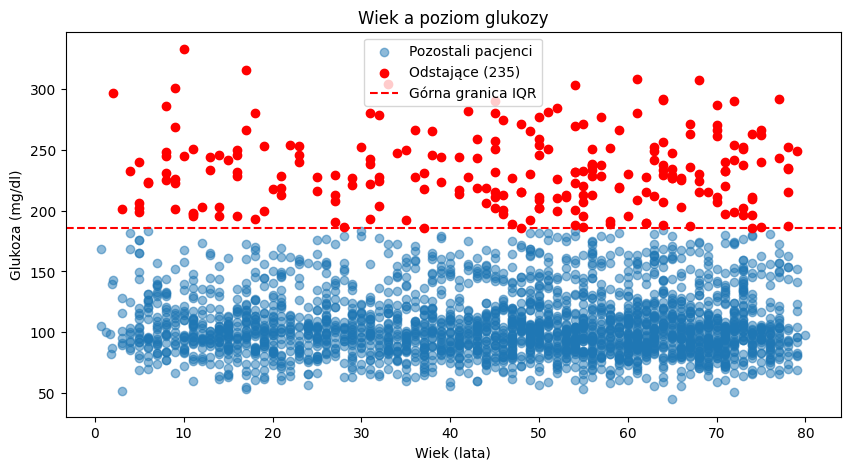

In [ ]:
# TODO: wykres punktowy z zaznaczonymi wartościami odstającymi


s = pacjenci["avg_glucose_level"]

odstajace = maska_iqr(s)

q1 = s.quantile(0.25)
q3 = s.quantile(0.75)
iqr = q3 - q1
gorna = q3 + 1.5 * iqr

fig, ax = plt.subplots(figsize=(10, 5))

# Pacjenci bez wartości odstających
ax.scatter(
    pacjenci.loc[~odstajace, "age"],
    pacjenci.loc[~odstajace, "avg_glucose_level"],
    label="Pozostali pacjenci",
    alpha=0.5
)

# Pacjenci z odstającą glukozą
ax.scatter(
    pacjenci.loc[odstajace, "age"],
    pacjenci.loc[odstajace, "avg_glucose_level"],
    color="red",
    label=f"Odstające ({odstajace.sum()})"
)

# Linia górnej granicy IQR
ax.axhline(
    y=gorna,
    color="red",
    linestyle="--",
    label="Górna granica IQR"
)

ax.set_title("Wiek a poziom glukozy")
ax.set_xlabel("Wiek (lata)")
ax.set_ylabel("Glukoza (mg/dl)")
ax.legend()

plt.show()


### Czy wartość odstająca niesie informację?

Wysoki poziom glukozy może być związany z udarem. Porównaj odsetek udarów (`stroke`) wśród pacjentów z glukozą odstającą (IQR 1,5) i wśród pozostałych. Narysuj wykres pudełkowy glukozy w podziale na `stroke`.

Udar przy odstającej glukozie: 21.7 %
Udar u pozostałych: 21.92 %


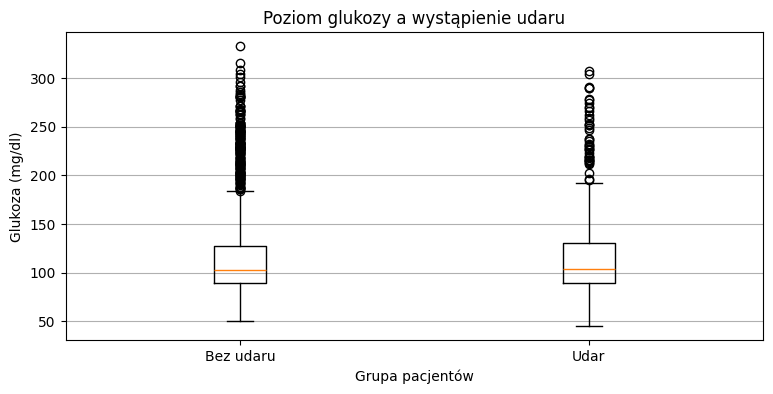

In [56]:
# TODO: odsetek udarów w obu grupach
odstajace = maska_iqr(pacjenci["avg_glucose_level"])

udar_odstajace = pacjenci.loc[odstajace, "stroke"].mean() * 100
udar_pozostali = pacjenci.loc[~odstajace, "stroke"].mean() * 100

print("Udar przy odstającej glukozie:", round(udar_odstajace, 2), "%")
print("Udar u pozostałych:", round(udar_pozostali, 2), "%")

# TODO: boxplot glukozy w podziale na stroke
plt.figure(figsize=(9, 4))

plt.boxplot([
    pacjenci.loc[pacjenci["stroke"] == 0, "avg_glucose_level"].dropna(),
    pacjenci.loc[pacjenci["stroke"] == 1, "avg_glucose_level"].dropna()
], tick_labels=["Bez udaru", "Udar"])

plt.title("Poziom glukozy a wystąpienie udaru")
plt.xlabel("Grupa pacjentów")
plt.ylabel("Glukoza (mg/dl)")
plt.grid(axis="y")

plt.show()

✍️ **Pytanie:** Czy pacjentów z wysoką glukozą należy usunąć z danych, jeśli chcemy przewidywać udar?

*Odpowiedź:* W analizowanym zbiorze odsetek udarów wśród pacjentów z odstającą glukozą wyniósł 21,70%, a wśród pozostałych 21,92%. Różnica jest niewielka, więc na podstawie tej analizy nie widać wyraźnego związku między odstającym poziomem glukozy a wystąpieniem udaru.

## 2.4 Krok 3: nielogiczne kombinacje kategorii

Każda wartość osobno może być poprawna („dziecko”, „pali”), a niemożliwa jest dopiero ich kombinacja.

1. Zrób tabelę krzyżową `work_type` × `smoking_status` (`pd.crosstab`). Co jest podejrzane?
2. Utwórz maski:
   - `dziecko_pali` — `work_type == "children"` i `smoking_status` to `"smokes"` lub `"formerly smoked"`,
   - `maluch_student` — wiek ≤ 3 lata i `work_type == "student"`.
3. Wyświetl znalezionych pacjentów.

In [60]:
# TODO: tabela krzyżowa
tabela = pd.crosstab(pacjenci["work_type"], pacjenci["smoking_status"])
display(tabela)

# TODO: maski
dziecko_pali = (
    (pacjenci["work_type"] == "children") &
    (pacjenci["smoking_status"].isin(["smokes", "formerly smoked"]))
)
maluch_student = (
    (pacjenci["age"] <= 3) &
    (pacjenci["work_type"] == "student")
)

pacjenci["smoking_status"].isin(["smokes", "formerly smoked"])


print("Dzieci palące lub wcześniej palące:", dziecko_pali.sum())
print("Studenci w wieku do 3 lat:", maluch_student.sum())

# Łączymy obie maski
nielogiczne = dziecko_pali | maluch_student

print("Łącznie podejrzanych pacjentów:", nielogiczne.sum())

# Wyświetlamy podejrzane rekordy
display(pacjenci.loc[nielogiczne, [
    "age", "work_type", "smoking_status"
]])

smoking_status,Unknown,formerly smoked,never smoked,smokes
work_type,,,,
Govt_job,16,63,94,67
Never_worked,1,30,36,35
Private,76,440,585,445
Self-employed,18,137,166,131
children,17,0,274,15
student,22,67,190,75


Dzieci palące lub wcześniej palące: 15
Studenci w wieku do 3 lat: 1
Łącznie podejrzanych pacjentów: 16


,age,work_type,smoking_status
52,1.80,student,formerly smoked
111,9.00,children,smokes
290,13.00,children,smokes
336,12.00,children,smokes
352,14.00,children,smokes
361,2.00,children,smokes
578,3.00,children,smokes
600,10.00,children,smokes
613,13.00,children,smokes
741,13.00,children,smokes


✍️ **Pytanie:** Czy IQR albo z-score mogłyby wykryć te przypadki? Dlaczego?

*Odpowiedź:* Metody IQR i Z-score nie wykryłyby bezpośrednio tych przypadków, ponieważ analizują odstające wartości liczbowe, a nie zależności między kategoriami

## 2.5 Krok 4: nietypowe kombinacje liczb — odległość od środka

Liczymy kwadrat **odległości euklidesowej** każdego pacjenta od środka danych, po standaryzacji cech:

$$d^2 = \sum_j \left(\frac{x_j - \bar{x}_j}{s_j}\right)^2$$

Dla danych o rozkładzie normalnym $d^2$ ma rozkład $\chi^2$ z $p$ stopniami swobody ($p$ = liczba cech), więc próg bierzemy z kwantyla 0,99.

1. Weź kolumny `LICZBOWE` bez braków (`dropna`) → `X`.
2. Wystandaryzuj je i policz `d2`.
3. Wyznacz próg `chi2.ppf(0.99, df=3)` i policz, ilu pacjentów go przekracza.
4. Sprawdź, **która cecha** ma największy udział w $d^2$ u tych pacjentów (`idxmax(axis=1)` na kwadratach z-score'ów).

In [61]:
from scipy.stats import chi2

# TODO
X = pacjenci[LICZBOWE].dropna()
Z = (X - X.mean()) / X.std()
d2 = (Z ** 2).sum(axis=1)
prog = chi2.ppf(0.99, df=3)
odstajacy = d2 > prog

print("Próg:", round(prog, 2))
print("Liczba odstających pacjentów:", odstajacy.sum())


Próg: 11.34
Liczba odstających pacjentów: 73


Glukoza jest silnie prawoskośna, więc odległość wskazuje głównie jej długi ogon. Powtórz obliczenia po zlogarytmowaniu glukozy (`np.log`) i porównaj liczbę odstających. Narysuj wykres punktowy `bmi` × `avg_glucose_level`, zaznaczając pacjentów odstających po transformacji.

Przed logarytmowaniem: 73
Po logarytmowaniu: 31


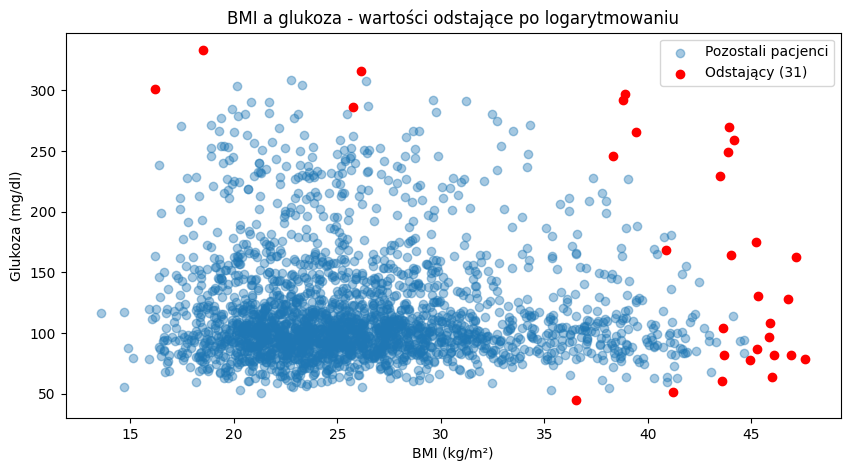

                   age   bmi  avg_glucose_level
age               1.00  0.02               0.01
bmi               0.02  1.00              -0.02
avg_glucose_level 0.01 -0.02               1.00


In [64]:
# TODO: X_log, Z_log, d2_log i liczba odstających
X_log = X.copy()
X_log["avg_glucose_level"] = np.log(X_log["avg_glucose_level"])
Z_log = (X_log - X_log.mean()) / X_log.std()
d2_log = (Z_log ** 2).sum(axis=1)
odstajacy_log = d2_log > prog

print("Przed logarytmowaniem:", odstajacy.sum())
print("Po logarytmowaniu:", odstajacy_log.sum())

# TODO: wykres punktowy

fig, ax = plt.subplots(figsize=(10, 5))

# Pozostali pacjenci
ax.scatter(
    X.loc[~odstajacy_log, "bmi"],
    X.loc[~odstajacy_log, "avg_glucose_level"],
    alpha=0.4,
    label="Pozostali pacjenci"
)

# Pacjenci odstający
ax.scatter(
    X.loc[odstajacy_log, "bmi"],
    X.loc[odstajacy_log, "avg_glucose_level"],
    color="red",
    label=f"Odstający ({odstajacy_log.sum()})"
)

ax.set_title("BMI a glukoza - wartości odstające po logarytmowaniu")
ax.set_xlabel("BMI (kg/m²)")
ax.set_ylabel("Glukoza (mg/dl)")
ax.legend()

plt.show()
print(X.corr().round(2))

✍️ **Pytanie:** Wiek, BMI i glukoza są tu prawie nieskorelowane (sprawdź `X.corr()`). Czy w takiej sytuacji odległość Mahalanobisa dałaby coś więcej niż euklidesowa?

*Odpowiedź:* Po zlogarytmowaniu glukozy liczba wartości odstających spadła z 73 do 31 (o 57,5%). Transformacja zmniejszyła wpływ skrajnych wartości glukozy. Korelacje między zmiennymi są bliskie zeru, więc odległość Mahalanobisa nie dałaby znacząco innych wyników niż euklidesowa na danych standaryzowanych.

### Dla chętnych: Isolation Forest

Użyj `sklearn.ensemble.IsolationForest` (`contamination=0.01`, `random_state=0`) na `X_log`. Ilu pacjentów wskazuje jednocześnie Isolation Forest i odległość `d2_log`?

In [ ]:
# TODO (dla chętnych)


## 2.6 Krok 5: podsumowanie i decyzja

Zbierz wyniki wszystkich kroków w jednej ramce `flagi` (jeden wiersz na pacjenta, indeks jak w `oryginal`) z kolumnami logicznymi:

- `niemozliwa_wartosc` (krok 1),
- `glukoza_iqr` (krok 2, IQR 1,5 dla glukozy),
- `nielogiczna_kategoria` (krok 3),
- `odlegly_od_srodka` (krok 4, `d2_log`; pacjenci bez obliczonej odległości → `False`).

Policz, ilu pacjentów ma każdą flagę i ilu ma co najmniej jedną.

In [65]:
# TODO: ramka flagi

flagi = pd.DataFrame(index=oryginal.index)
flagi["niemozliwa_wartosc"] = zly_pacjent

flagi["glukoza_iqr"] = maska_iqr(
    pacjenci["avg_glucose_level"]
)

flagi["nielogiczna_kategoria"] = dziecko_pali | maluch_student

flagi["odlegly_od_srodka"] = (d2_log > prog).reindex(
    oryginal.index, fill_value=False
)

print("Liczba pacjentów w każdej grupie:")
print(flagi.sum())

print("\nPacjenci z co najmniej jedną flagą:")
print(flagi.any(axis=1).sum())

display(flagi.head())



Liczba pacjentów w każdej grupie:
niemozliwa_wartosc       560
glukoza_iqr              235
nielogiczna_kategoria     16
odlegly_od_srodka         31
dtype: int64

Pacjenci z co najmniej jedną flagą:
806


,niemozliwa_wartosc,glukoza_iqr,nielogiczna_kategoria,odlegly_od_srodka
0,False,False,False,False
1,False,False,False,False
2,False,False,False,False
3,False,False,False,False
4,False,False,False,False


✍️ **Decyzja:** dla każdej grupy zaproponuj strategię i uzasadnij ją jednym zdaniem.

| Grupa | Strategia (poprawić / NaN / usunąć / przyciąć / log / zostawić / flaga) | Uzasadnienie |
|---|---|---|
| wartości niemożliwe | NaN | Są to błędy techniczne |
| wysoka glukoza (IQR) | Zostawić | Może być prawdziwym pomiarem |
| nielogiczne kategorie | Flaga/Poprawić | Wymagają weryfikacji |
| odlegli od środka | Flaga | flaga pozwala zachować nietypowe przypadki |